# Automated parameter selection

The model has 37 kinetic parameters but 22 conditions of noisy steady-state data cannot determine them all. The selection builds an **identifiable parameter structure**: it starts with all 37 parameters free (*stage 0*) and then fixes parameters one rule at a time, at their anchored (fitted) values, until the data can determine what is left. Everything is automatic and deterministic; the thresholds are in `settings/thresholds.csv`, the code in `src/selection.py` (loop and stage 0), `src/identifiability/` (structural check, practical analysis, rules) and `src/estimation/refit.py` (refits). The settings of a run are the dict `params` of section 7 (`default_params("selection")`, read from the CSV files).

The notebook is organised as

1. the method, with the equations of every rule (sections 1 to 5);
2. a small numerical illustration of the Schur complement (section 6);
3. the run: stage 0 and the reduction loop (section 7, behind `RUN`);
4. the results of a run: iteration table, free set per iteration, per-iteration diagnostics, final structure (sections 8 to 12).

With `HK_RUN=0` (the default) sections 8 to 12 read the files of `OUT`; `HK_RUN=1` first runs sections 7. The same run is available from the command line: `python src/selection.py --out results_v4/flux_model`.

## 1. What is analysed: the profiled model and its Fisher information

**Estimation problem.** Per condition $e$ the free variables $w_e = (x_e, u_e, b_e)$ (balanced metabolites, cofactors, free drains) satisfy $S\,v(x_e,u_e,E_e;\theta) = b_e$ and box bounds (see `model.ipynb`). The kinetic parameters $\theta \in \mathbb{R}^p$ are shared; $p$ is the number of *free* parameters, the others are held at their anchored values.

**Reduced (profiled) model.** For fixed $\theta$ every condition solves its inner problem

$$ w_e^*(\theta) = \arg\min_{w_e}\; \tfrac12 \sum_k \big((y_{ek} - \hat y_k(w_e;\theta))/\sigma_k\big)^2 \quad\text{s.t. steady state and bounds}, \qquad y^*_{ek}(\theta) = \hat y_k\big(w_e^*(\theta);\theta\big). $$

This is the problem that is actually estimated: the free cofactors and drains re-adjust when $\theta$ changes and absorb part of the change. Sensitivities at fixed $(x,u,b)$ (implicit function theorem) would miss that and, for instance, rank `v_max_1` as very influential while the free glucose and pyruvate cancel it.

**Weighted reduced sensitivity.** With finite differences in $\ln\theta$ (`sens_step` $h = 10^{-2}$, forward/backward consistency check, a column check at $h = 3\cdot 10^{-3}$, one-sided steps at the theta bounds; entries that fail are flagged, never set to zero silently):

$$ J_{(e,k),\,j} \;=\; \frac{\theta_j}{\sigma_k}\,\frac{\partial y^*_{ek}}{\partial \theta_j}, \qquad F = J^\top J \;\in\; \mathbb{R}^{p\times p}\quad(\text{FIM in the log-parameters}). $$

The *influence* of a parameter is the RMS of its column of $J$, $\;\iota_j = \big(\operatorname{mean}_{(e,k)} J_{(e,k),j}^2\big)^{1/2}$.

## 2. Nuisance parameters and the Schur complement

Some parameters cannot be fixed by the rules: the forward catalytic constants $k_\mathrm{cat}$ (`protected_params.csv`) and the last free parameter of each reaction (every rate equation keeps at least one free parameter). If such a parameter is *output-level non-identifiable* (the free cofactors and drains absorb it, section 3) it still has to stay in the model; it is then a **nuisance** parameter (`kept_free_by_rule`). Nuisance parameters must not make the others look identifiable or non-identifiable, so every practical criterion is computed on the other parameters *after profiling the nuisance ones out*. With $b$ = nuisance and $a$ = the rest:

$$ F_S \;=\; F_{aa} - F_{ab}\,F_{bb}^{+}\,F_{ba} \qquad\Longleftrightarrow\qquad J_S = (I - P_b)\,J_a,\;\; P_b = \text{orthogonal projector on the column space of } J_b, \qquad F_S = J_S^\top J_S . $$

* **Rank** at the eigenvalue cut: $\operatorname{rank} = \#\{k:\ \lambda_k/\lambda_1 > \varepsilon\}$ with $\lambda_k$ the eigenvalues of $F_S$ and $\varepsilon = $ `eig_cut` $= 10^{-8}$ (the same as a singular-value ratio of $10^{-4}$ of $J_S$). This is the only rank cut of the method.
* **Correlation** from the pseudo-inverse, $r_{ij} = [F_S^+]_{ij}\big/\sqrt{[F_S^+]_{ii}[F_S^+]_{jj}}$ (a parameter pair can be individually informative and still have $|r|\approx 1$: only a combination of the two is determined).
* **Covariance and CV** in the log-parameters, $\operatorname{Cov}(\hat\theta) \approx D\,F_S^{+}D$ with $D = \operatorname{diag}(\theta)$; the nuisance block uses $F_{bb}^+$ and is reported separately (it is conditional and bound driven).
* **Flags**: an entry of $J$ that sits at a theta bound (`at_bound`), whose finite differences are inconsistent (`fd_unstable`) or that failed (`fd_failed`) carries no trustworthy information.

## 3. The structural check (every iteration)

Practical analysis at a fitted point can only say what *this* data set can determine. A **structural** null direction cannot be determined by any data, so it is removed first, at the start of every iteration. Two tests, both restricted to the currently free parameters and both repeated for $q+1$ parameter realizations ($\theta_i = \hat\theta\,e^{U(\ln 0.5,\ \ln 1.5)}$, the anchor is realization 0; `structural_q` = 10 and `structural_q_out` = 5):

**Rate level (Stigter and Molenaar 2015).** The outputs are the 9 reaction rates $v_r(x,u,E;\theta)$ evaluated at the fitted states of all conditions; the relative output sensitivity matrix $S_{ij} = \theta_j\,\partial v_i/\partial\theta_j\,/\,v_i$ is computed exactly (CasADi Jacobians of the very same rate-law code the estimator uses). A direction is a **structural zero** if $\sigma_k/\sigma_{\max} < 10^{-10}$ for its singular value in **all** realizations; the consensus null space is the intersection of the per-realization null spaces, its coordinate projector gives the **null groups** (parameters that only appear in a combination), a sparse basis gives the combination (e.g. $\ln K_{s,f6p} - \ln K_{s,atp}$ only appears as a product), and a symbolic (sympy) null-vector computation confirms the exact ones: groups are `exact`, `mixed` or `point-dependent` (null at this anchor only). See `structural_identifiability.ipynb`.

**Output level.** The estimation problem has free per-condition variables $w_e$ that can absorb a rate change. With $A_e = [F_w;\,h_w]$ and $B_e = [F_\theta;\,h_\theta]$ (Jacobians of the steady-state constraint $F = S v - b$ and of the measured outputs $h$ with respect to $w$ and $\theta$) and $Q_e = I - A_eA_e^{+}$, the stacked matrix $Q_eB_e$ (rows scaled by $1/\sigma$) has a null space exactly where a change of $\theta$ can be absorbed in every condition. Version (i) ignores the bounds of $w$ (structural verdict); version (ii) pins every $w$ that sits on a bound at the anchor. Classes per parameter: `identifiable`, `bound_identified` (identifiable only through an active bound) and `non_identifiable`.

**Structural fixes.** Per null group, the member with the highest influence stays free, the others are fixed at their anchored values (`rules.choose_fixes`: candidates in ascending influence, ties within 25% broken by the room to the theta bounds, fixing a set removes the null space iff the corresponding columns of the group basis form an invertible matrix). Members the protections forbid to fix (see section 5) become the nuisance set. After the fixes the problem is refitted and the check repeated (at most `max_structural_rounds` rounds).

## 4. The rules of the practical analysis

After a clean structural check the practical analysis (Schur complement of section 2) is evaluated and the **first rule that fires** acts. Each iteration fixes exactly **one** parameter, except rule R0 (an exact, batch action). Fixed parameters keep their anchored values.

| rule | trigger | action |
|---|---|---|
| **R0** zero influence | $\iota_j < $ `zero_cut` $\cdot \max_i \iota_i$ ($10^{-6}$): the parameter has no effect on any measured output | fix all of them (lowest influence first); the FIM does not change |
| **R1** SVD | the FIM $F_S$ is **rank deficient** at the eigenvalue cut: $\#\{\lambda_k/\lambda_1 > 10^{-8}\} < n_a$ | take the right singular vector $v$ of the smallest singular value of $J_S$ (restricted to the parameters with non-zero influence); fix the fixable parameter with the largest $\lvert v_j\rvert$; loadings within `svd_tie_tol` (5%) of the top one count as tied and the one with the **lowest influence** is fixed; if the top fixable loading is below `svd_min_loading` (0.05) the vector is unresolved |
| **R2** correlation | the FIM is **full rank** and some pair has $\lvert r_{ij}\rvert >$ `corr_threshold` (0.9) | take the pair with the largest $\lvert r\rvert$ that has a fixable member; fix the member with the **lower influence** (the other one if that is not fixable) |
| **R3** flags | a free non-nuisance parameter is flagged (`at_bound`, `fd_unstable`, `fd_failed`) | fix the fixable flagged parameter with the lowest influence |

The correlation rule is only used on a full-rank FIM because a pseudo-inverse of a rank-deficient matrix gives meaningless correlations; while the matrix is rank deficient only R0 and R1 can act. After the single fix the problem is **refitted** (next section) and the loop continues with the new anchor.

## 5. Refits, protections and the stopping rule

**Monotone refit.** Fixing a parameter at its anchored value keeps the anchor feasible with the *same* objective, so a refit that ends higher than the anchor has failed. `refit.refit_with_fixed` warm starts at the anchor primal point (theta, $x$, $u$, $b$) with the tight monotone IPOPT options (attempt 1), the default options (2) and a monotone barrier (3), each followed by `refine_anchor` (strict improvements only), and accepts the first result with

$$ \text{obj}_\text{after} \;\le\; \text{obj}_\text{anchor}\,(1 + 10^{-6}) + 10^{-9}. $$

A start from the data is never used; if every attempt fails the anchor itself is kept (`refit_status = kept_anchor`). Every `multistart_every` iterations (3) a 15-start recorded multistart searches the theta box around the current structure and a candidate is adopted only if it is strictly better.

**Protections.** (a) Parameters whose name starts with a prefix of `protected_params.csv` (`kcat_f_`) are never fixed. (b) Every reaction group (one per rate equation, `model.parameters.reaction_groups`) keeps **at least one free parameter**; only the PTS group has no $k_\mathrm{cat}$, so there the rule binds. The members the protections keep free in an unresolved structural group become nuisance parameters (section 2).

**Stopping rule.**

* `converged`: the FIM $F_S$ is full rank at the eigenvalue cut, no pair among the non-nuisance free parameters has $\lvert r\rvert >$ 0.9, none of them is flagged, no violation is unresolved and the final structural check explains whatever it still flags by the protected parameters;
* `stuck`: no rule can fix anything (the violations are fixed by no legal move); the unresolved violations are listed and **never reported as identifiable**;
* `structural_unresolved` (a flagged structural group without a fixable member, or still flagged after `max_structural_rounds` rounds) and `max_iter` for the other ways to stop.

Also: iteration 0 is the structural pre-pass at the stage-0 anchor (the check, the fixes and the refits of its rounds all belong to iteration 0), and the loop ends with a final structural check that never fixes anything.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import check_out_dir, resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.RUN["out_dir"])   # default: out_dir of settings/run.csv; relative paths are relative to the repo root
RUN = os.environ.get("HK_RUN", "0") == "1"

try:
    check_out_dir(OUT)
    WRITABLE = True
except ValueError:
    WRITABLE = False

if RUN and not WRITABLE:
    raise ValueError("HK_RUN=1 refuses an output directory inside results/, results_v2/ or results_v3/: %s" % OUT)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("REPO     :", REPO)
print("OUT      :", OUT)
print("RUN      :", RUN, "(False = load the saved results of OUT; True = compute and save into OUT)")
print("WRITABLE :", WRITABLE, "(tables / figures / report are written to OUT only if True)")

import glob
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import selection
from settings import THRESHOLDS, RUN as RUN_SETTINGS, default_params, snapshot_settings
from model.parameters import ALL_PARAMS, RXN_OF_PARAM, RXN_ORDER
from estimation.anchors import check_bounds, restore_anchor

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)

RED = os.path.join(OUT, "reduction")
STAGE0 = os.path.join(OUT, "stage0")

def read_optional(path, **kw):
    """pd.read_csv, or None with a message if the file is not there (e.g. an output only a newer run writes)."""
    if os.path.exists(path):
        return pd.read_csv(path, **kw)
    print("not found (written only by a newer run?): " + os.path.relpath(path, OUT))
    return None

REPO     : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733
OUT      : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results_v4/flux_model
RUN      : True (False = load the saved results of OUT; True = compute and save into OUT)
WRITABLE : True (tables / figures / report are written to OUT only if True)


## 6. A small numerical illustration of the Schur complement

Four parameters, 40 rows of a synthetic $J$. Parameter 3 is almost a copy of parameter 0, and parameter 0 is the nuisance one. The Schur complement is the information of the others *after* the nuisance parameter has been profiled out; it equals the orthogonal projection of the remaining columns off the nuisance columns.

In [2]:
rng = np.random.default_rng(0)
J_toy = rng.normal(size=(40, 4))
J_toy[:, 3] = J_toy[:, 0] + 1e-5 * rng.normal(size=40)

nuis, keep = [0], [1, 2, 3]
F_toy = J_toy.T @ J_toy
F_schur = F_toy[np.ix_(keep, keep)] - F_toy[np.ix_(keep, nuis)] @ np.linalg.pinv(F_toy[np.ix_(nuis, nuis)]) @ F_toy[np.ix_(nuis, keep)]

P_b = J_toy[:, nuis] @ np.linalg.pinv(J_toy[:, nuis])
J_S = (np.eye(40) - P_b) @ J_toy[:, keep]
print("F_S equals J_S^T J_S: %s" % np.allclose(F_schur, J_S.T @ J_S))

eig_cut = THRESHOLDS["eig_cut"]
for name, F in (("full FIM (4 parameters)", F_toy), ("Schur complement (3 parameters)", F_schur)):
    w = np.linalg.eigvalsh(F)[::-1]
    print("%-32s eigenvalue ratios %s -> rank %d of %d at the cut %.0e" % (
        name, np.array2string(w / w[0], precision=1), int((w / w[0] > eig_cut).sum()), len(w), eig_cut))

F_S equals J_S^T J_S: True
full FIM (4 parameters)          eigenvalue ratios [1.0e+00 6.8e-01 5.2e-01 2.8e-11] -> rank 3 of 4 at the cut 1e-08
Schur complement (3 parameters)  eigenvalue ratios [1.0e+00 7.6e-01 8.3e-11] -> rank 2 of 3 at the cut 1e-08


## 7. Run: stage 0 and the reduction loop

Skipped unless `HK_RUN=1`. Everything is written below `OUT` (the notebook refuses `results/`, `results_v2/` and `results_v3/`). Switches (environment variables): `HK_N_JOBS` (workers), `HK_FROM_ANCHOR` (a directory with `anchor_state.pkl`: skip stage 0 and start the reduction from it), `HK_RESUME` (reuse an existing `OUT/stage0` and continue from `OUT/reduction/checkpoint.pkl`). Everything else is set in the two `params` cells below; their defaults are the CSV files of `settings/`, so a run that changes nothing reproduces the published structure.

First the asserted precondition of every run: the bounds contain every measured value. The settings of the run are copied to `OUT/settings_used/`.

In [3]:
N_JOBS = int(os.environ.get("HK_N_JOBS", RUN_SETTINGS["n_jobs"]))
FROM_ANCHOR = os.environ.get("HK_FROM_ANCHOR") or None
RESUME = os.environ.get("HK_RESUME", "0") == "1"

if RUN:
    os.makedirs(OUT, exist_ok=True)
    check_bounds()
    snapshot_settings(OUT)

[     1s] check_bounds_contain_data: OK (balanced, cofactors, drains); Pi bounds (1.0, 20.0)


**Stage 0** (`selection.run_stage0`): all 37 parameters free. Candidate A is the saved anchor named in `settings/run.csv` (`stage0_warm_start`: `Data/stage0_warm_start`, the stage-0 anchor of the v2 run, clipped into the current bounds) refined with the tight options; candidate B is the best start of a 50-start log-uniform multistart (every run recorded in `multistart_recorded.csv`) re-run in-process and refined. The better one is the stage-0 anchor (`anchor_state.pkl`, `theta_full.csv`, `objective_breakdown.csv`, `stage_row.json`, ...). Without the saved anchor the multistart starts from the literature values. With `HK_FROM_ANCHOR` the files of that directory are copied into `OUT/stage0` instead.

In [4]:
# Settings of stage 0 (defaults from settings/run.csv and settings/thresholds.csv)
stage0_params = default_params("stage0")
stage0_params["n_starts_stage0"] = 50   # random starts of the multistart with all 37 parameters free
stage0_params["n_jobs"] = N_JOBS        # worker processes (HK_N_JOBS)
stage0_params

{'n_jobs': 8,
 'stage0_seed': 0,
 'stage0_warm_start': 'Data/stage0_warm_start',
 'n_starts_stage0': 50,
 'theta_at_bound_tol': 0.01}

In [5]:
if RUN and FROM_ANCHOR:
    ANCHOR_DIR = selection.copy_anchor_files(FROM_ANCHOR, STAGE0)
    print("starting from the saved anchor %s (stage 0 skipped)" % ANCHOR_DIR)
elif RUN and RESUME and os.path.exists(os.path.join(STAGE0, "anchor_state.pkl")):
    ANCHOR_DIR = STAGE0
    print("resuming: reusing the stage 0 anchor of", STAGE0)
elif RUN:
    ANCHOR_DIR = selection.run_stage0(OUT, stage0_params)
else:
    print("RUN is False: stage 0 is loaded from", STAGE0)

[     1s] check_bounds_contain_data: OK (balanced, cofactors, drains); Pi bounds (1.0, 20.0)


[     1s] stage0: 22 conditions, warm start from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/Data/stage0_warm_start (obj 60.3718 under its own bounds)


[     3s] candidate A (saved anchor primal, clipped): single fit obj 18.03542


[     6s] candidate A refined obj 15.12709


[    96s] multistart done in 90s: 47/51 converged, best obj 12.32442, warm start 27.02643, median 74.89915


[    99s] candidate B (best multistart start re-run in-process): obj 12.32442 (table 12.32442)


[   102s] candidate B refined obj 11.74548


[   102s] using candidate multistart_best: obj 11.74548


[   103s] stage0 saved: obj 11.74548 (mean breakdown 11.73238) s2 2.94; rmse_met 0.1207 (baseline 0.1576); LI flux rmse 0.4119 (baseline 0.7270); 8 drain values at bound; 2 theta at bounds


**Reduction loop** (`selection.run_reduction`). The stage-0 anchor is restored with the tight warm start (`restore_anchor`); every iteration then runs the structural check (`StructuralCheck`), the practical analysis and at most one fix with its refit. It writes `OUT/reduction/` (`iterations.csv`, `fixing_log.csv`, `reduction.log`, `structural_per_iteration.csv`, `structural_spectra/`, `iter_XX/` with `free_params.csv` and `next_free_params.csv`, `final_free_params.csv`, `final_structure.csv`, `final_anchor_state.pkl`, `reduction_summary.json`, `checkpoint.pkl`).

In [6]:
# Settings of the parameter selection (defaults from settings/thresholds.csv)
params = default_params("selection")
params["corr_threshold"] = 0.9      # |r| above this counts as correlated (rule R2, used at full rank only)
params["eig_cut"] = 1e-8            # the rank cut: eigenvalue ratio of the FIM (rule R1)
params["zero_cut"] = 1e-6           # influence below this times the largest is a structural zero (rule R0)
params["max_iter"] = 30             # at most this many iterations
params["multistart_every"] = 3      # a multistart every this many iterations (0: only before the loop stops)
params["n_starts"] = 15             # random starts of those multistarts
params["n_jobs"] = N_JOBS           # worker processes (HK_N_JOBS)
params

{'n_jobs': 8,
 'max_iter': 30,
 'max_structural_rounds': 6,
 'svd_tie_tol': 0.05,
 'svd_min_loading': 0.05,
 'multistart_every': 3,
 'n_starts': 15,
 'multistart_top_n': 2,
 'multistart_max_ratio': 1.05,
 'end_multistart_rtol': 1e-06,
 'refit_rtol': 1e-06,
 'refit_atol': 1e-09,
 'sens_step': 0.01,
 'sens_step_check': 0.003,
 'fd_consistency_rtol': 0.1,
 'fd_consistency_atol': 0.001,
 'corr_threshold': 0.9,
 'zero_cut': 1e-06,
 'eig_cut': 1e-08,
 'structural_q': 10,
 'structural_q_out': 5,
 'seed_base': 1000,
 'final_seed_base': 9000,
 'perturb_seed_offset': 5000,
 'structural_sv_tol': 1e-10,
 'structural_guard_rel': 1e-06,
 'structural_load_min': 0.05,
 'tie_rtol': 0.25,
 'realization_lo': 0.5,
 'realization_hi': 1.5,
 'perturb_lo': 0.5,
 'perturb_hi': 2.0,
 'output_realization_lo': 0.5,
 'output_realization_hi': 2.0,
 'output_perturb_lo': 0.5,
 'output_perturb_hi': 2.0,
 'active_rtol': 0.0001,
 'rank_rcond': 1e-10}

In [7]:
if RUN:
    est, state = restore_anchor(ANCHOR_DIR)
    est, status = selection.run_reduction(est, OUT, params, resume=RESUME)
    print("status:", status, "| free:", len(est.free_params))
else:
    print("RUN is False: the reduction is loaded from", RED)

[   105s] anchor restored: obj 11.745506 (first warm-start solve 11.745506, saved 11.745483)


symbolic pts: generic nullity 0 (verified True) [0.5s]


symbolic pgi: generic nullity 0 (verified True) [0.1s]


symbolic pfk: generic nullity 2 (verified True) [0.2s]


symbolic fba: generic nullity 1 (verified True) [0.1s]


symbolic tpi: generic nullity 0 (verified True) [0.1s]


... (193 outputs left out)

[  1384s]   structural FINAL it 8 round final: 11 free, sigma_min/max anchor 2.89e-04, min over 11 runs 1.06e-04, gap to next 2.0 decades, runs below cut 0, null dim 0 (perturbed states 0); groups: pts:K_g6p_1[output-level,dim1,exact0] | pfk:kcat_f_3[output-level,dim1,exact0] | gap:kcat_f_6[output-level,dim1,exact0] | pgk:kcat_f_7[output-level,dim1,exact0]


[  1492s] reduction finished: status converged, 11 free, wall 1385s


[  1492s] saved final anchor: 11 free, obj 10.920253, status converged, kept_free_by_rule ['K_g6p_1', 'kcat_f_3', 'kcat_f_6', 'kcat_f_7']


status: converged | free: 11


## 8. Stage 0 (all 37 parameters free)

Objective of the stage-0 anchor, the quality of the fit and the multistart. The recorded multistart table shows how rugged the objective is: only the best start comes close to the minimum, the median start is far above it, which is why the loop repeats a smaller multistart every third iteration.

In [8]:
stage_row = None
if os.path.exists(os.path.join(STAGE0, "stage_row.json")):
    stage_row = json.load(open(os.path.join(STAGE0, "stage_row.json")))
    keys = ["n_free", "obj", "s2", "candidate_used", "obj_b2sd_primal", "obj_multistart_best", "multistart_n_converged",
            "multistart_n_total", "multistart_median", "n_within_0.01_of_best", "rmse_met", "rmse_met_meanbaseline",
            "rmse_flux_li", "rmse_flux_li_meanbaseline", "n_drains_at_bound", "theta_at_bounds"]
    display(pd.Series({k: stage_row[k] for k in keys if k in stage_row}, name="stage 0").to_frame())
else:
    print("stage0/stage_row.json not found")

multistart = read_optional(os.path.join(STAGE0, "multistart_recorded.csv"))
if multistart is not None:
    conv = multistart[multistart["converged"]]
    print("%d starts, %d converged; objective of the converged starts: best %.3f, median %.3f, worst %.3f" % (
        len(multistart), len(conv), conv["obj_value"].min(), conv["obj_value"].median(), conv["obj_value"].max()))
    display(multistart[["start", "is_warm_start", "converged", "obj_value", "wall_s"]].head(8))

,stage 0
n_free,37
obj,11.745483
s2,2.936371
candidate_used,multistart_best
obj_b2sd_primal,15.127089
obj_multistart_best,11.745483
multistart_n_converged,47
multistart_n_total,51
multistart_median,74.899153
n_within_0.01_of_best,1


51 starts, 47 converged; objective of the converged starts: best 12.324, median 74.899, worst 192.526


,start,is_warm_start,converged,obj_value,wall_s
0,15,False,True,12.324419,4.580260
1,40,False,True,14.598532,16.174918
2,20,False,True,18.151001,11.998539
3,19,False,True,24.387184,79.235588
4,11,False,True,24.516736,24.246952
5,0,True,True,27.026426,3.144517
6,17,False,True,27.846105,6.917417
7,45,False,True,28.710028,11.917338


## 9. The iteration table

One row per iteration (iteration 0 is the structural pre-pass). Columns: free parameters at the start (`n_free`), objective before and after the fix and refit, the rank of $F_S$ at the cut and the number of analysed (non-nuisance) parameters, the smallest singular ratio, the largest $|r|$, the number of pairs above 0.9, the flagged parameters, the parameters fixed in this iteration with the rule, the refit status and the multistart outcome.

In [9]:
iterations = read_optional(os.path.join(RED, "iterations.csv"))
if iterations is not None:
    wanted = ["iter", "n_free", "obj", "obj_before", "obj_after", "rank_at_cut", "rank_1e-8", "n_analysed", "n_nuisance",
              "sigma_ratio", "max_abs_r", "n_pairs_gt", "n_zero", "n_flagged", "refit_status", "struct_refit_status",
              "multistart", "reason", "unresolved"]
    display(iterations[[c for c in wanted if c in iterations.columns]].set_index("iter"))

,n_free,obj,obj_before,obj_after,rank_at_cut,rank_1e-8,n_analysed,n_nuisance,sigma_ratio,max_abs_r,n_pairs_gt,n_zero,n_flagged,refit_status,struct_refit_status,multistart,reason,unresolved
iter,,,,,,,,,,,,,,,,,,
0,37,11.745506,NaN,10.920253,NaN,15,NaN,NaN,1.160362e-23,1.000000,33,10,NaN,NaN,kept_anchor,NaN,Ks_atp_3:structural;Kp_adp_3:structural;Kp_g3p_4:structural;Ks_g3p...,NaN
1,18,10.920253,10.920253,10.920253,9.0,9,14.0,4.0,2.246948e-07,0.998829,0,0,1.0,kept_anchor,NaN,NaN,Kp_dhap_4:svd,NaN
2,17,10.920253,10.920253,10.920253,9.0,9,13.0,4.0,8.393161e-06,0.998829,0,0,1.0,kept_anchor,NaN,NaN,Ks_pep_9:svd,NaN
3,16,10.920253,10.920253,10.920253,9.0,9,12.0,4.0,1.138486e-05,0.998829,0,0,1.0,kept_anchor,NaN,kept,Kp_f6p_pgi:svd,NaN
4,15,10.920253,10.920253,10.920253,9.0,9,11.0,4.0,1.271065e-05,0.998829,0,0,1.0,kept_anchor,NaN,NaN,Ks_2pg_8:svd,NaN
5,14,10.920253,10.920253,10.920253,9.0,9,10.0,4.0,4.809047e-05,0.998829,0,0,1.0,kept_anchor,NaN,NaN,Ks_dhap_5:svd,NaN
6,13,10.920253,10.920253,10.920253,9.0,9,9.0,4.0,3.177752e-04,0.962953,1,0,1.0,kept_anchor,NaN,kept,Ks_3pg_8:corr,NaN
7,12,10.920253,10.920253,10.920253,8.0,8,8.0,4.0,3.872235e-04,0.795469,0,0,1.0,kept_anchor,NaN,NaN,Ks_2pg_9:flag,NaN
8,11,10.920253,10.920253,10.920253,7.0,7,7.0,4.0,4.271347e-04,0.795515,0,0,0.0,NaN,NaN,end_kept,NaN,NaN


In [10]:
summary_path = os.path.join(RED, "reduction_summary.json")
if os.path.exists(summary_path):
    red_summary = json.load(open(summary_path))
    print("status: %s | identifiable: %s | %d free, %d fixed | final objective %.5f | wall %.0f s" % (
        red_summary["status"], red_summary["identifiable"], red_summary["n_free"], len(red_summary["fixed"]),
        red_summary.get("obj_final_anchor", float("nan")), red_summary.get("wall_s", float("nan"))))
    print("kept free by the protections (nuisance):", red_summary.get("kept_free_by_rule"))
    print("unresolved:", red_summary.get("unresolved"))
else:
    print("reduction_summary.json not found")

status: converged | identifiable: True | 11 free, 26 fixed | final objective 10.92025 | wall 1385 s
kept free by the protections (nuisance): ['K_g6p_1', 'kcat_f_3', 'kcat_f_6', 'kcat_f_7']
unresolved: []


### Which rule fixed which parameter

`fixing_log.csv` has one row per fixed parameter: the iteration (and structural round), the rule (`structural_exact`, `structural_pointdep`, `structural_output`, `zero_influence`, `svd`, `corr`, `flag`), the partner it was compared with, the value it was fixed at, its influence, the SVD loading or $r$, and the trigger. For the output-level fixes `output_class_at_fix` records the class at the fix (identifiable / bound_identified / non_identifiable). The table is also saved as `fixing_log_with_classes.csv`.

In [11]:
fix_log = read_optional(os.path.join(RED, "fixing_log.csv"))
if fix_log is not None:
    fix_cls = fix_log.copy()
    if "output_class_at_fix" in fix_cls.columns:
        fix_cls["class_at_fix"] = fix_cls["output_class_at_fix"]
    if WRITABLE and "class_at_fix" in fix_cls.columns:
        fix_cls.drop(columns=["output_class_at_fix"]).to_csv(os.path.join(OUT, "fixing_log_with_classes.csv"), index=False)
    cols = ["param", "iter", "round", "stage", "rule", "partner", "value_fixed", "influence_param", "r", "svd_loading",
            "class_at_fix"]
    display(fix_cls[[c for c in cols if c in fix_cls.columns]])
    display(fix_cls.groupby("rule").size().rename("n parameters").to_frame())

,param,iter,round,stage,rule,partner,value_fixed,influence_param,r,svd_loading,class_at_fix
0,Ks_atp_3,0,0.0,structural,structural_exact,Ks_f6p_3,0.001972,6.865369e-01,NaN,NaN,non_identifiable
1,Kp_adp_3,0,0.0,structural,structural_exact,Kp_fbp_3,0.002101,6.863315e-01,NaN,NaN,non_identifiable
2,Kp_g3p_4,0,0.0,structural,structural_exact,Kp_dhap_4,5.538993,1.610152e-06,NaN,NaN,non_identifiable
3,Ks_g3p_6,0,0.0,structural,structural_exact,Ks_pi_6,0.005013,5.977163e-04,NaN,NaN,non_identifiable
4,Ks_nad_6,0,0.0,structural,structural_exact,Ks_pi_6,0.005013,5.977151e-04,NaN,NaN,non_identifiable
5,Kp_nadh_6,0,0.0,structural,structural_exact,Kp_pgp_6,2.996095,5.637182e-07,NaN,NaN,non_identifiable
6,Ks_pgp_7,0,0.0,structural,structural_exact,Ks_adp_7,0.001241,2.779808e-03,NaN,NaN,non_identifiable
7,Ks_3pg_7,0,0.0,structural,structural_exact,Ks_atp_7,3.654498,1.603780e-05,NaN,NaN,non_identifiable
8,Kp_pgp_6,0,1.0,structural,structural_pointdep,NaN,8.180164,2.875369e-06,NaN,NaN,non_identifiable
9,v_max_1,0,2.0,structural,structural_output,NaN,80.209416,1.989346e-03,NaN,NaN,non_identifiable


,n parameters
rule,
corr,1
flag,1
structural_exact,8
structural_output,10
structural_pointdep,1
svd,5


## 10. The free set at every iteration

`iter_XX/free_params.csv` is the free set analysed in iteration XX and `iter_XX/next_free_params.csv` the free set after its fix (columns `status`, anchored `value`, `reaction`). The matrix shows the free parameters at the start of every iteration (1 = free) and the last column the final structure. Runs that predate these files (the saved v3 run) have the matrix reconstructed from `fixing_log.csv` instead, one column per fixing step (the free set after the step).

In [12]:
free_files = sorted(glob.glob(os.path.join(RED, "iter_*", "free_params.csv")))
matrix = pd.DataFrame(index=pd.Index(ALL_PARAMS, name="param"))
if free_files:
    source = "iter_XX/free_params.csv"
    for f in free_files:
        status = pd.read_csv(f, index_col=0)["status"]
        matrix["it " + os.path.basename(os.path.dirname(f))[5:]] = (status.reindex(ALL_PARAMS) == "free").astype(int)
    final_free = read_optional(os.path.join(RED, "final_free_params.csv"), index_col=0)
    if final_free is not None:
        matrix["final"] = (final_free["status"].reindex(ALL_PARAMS) == "free").astype(int)
elif fix_log is not None:
    source = "reconstructed from fixing_log.csv (free set after each fixing step)"
    current = pd.Series(1, index=ALL_PARAMS)
    matrix["start"] = current
    for (it, rnd), grp in fix_log.groupby(["iter", "round"], sort=False, dropna=False):
        current = current.copy()
        current[list(grp["param"])] = 0
        structural_step = "stage" in grp.columns and grp["stage"].iloc[0] == "structural"
        matrix["after it %d.r%d" % (it, rnd) if structural_step else "after it %d" % it] = current
else:
    source = "not available"

if fix_log is not None:
    matrix["fixed by"] = fix_log.set_index("param")["rule"].reindex(ALL_PARAMS).fillna("")
    matrix["reaction"] = [RXN_OF_PARAM[p] for p in ALL_PARAMS]

print("free-set matrix from:", source)
matrix

free-set matrix from: iter_XX/free_params.csv


,it 00,it 01,it 02,it 03,it 04,it 05,it 06,it 07,it 08,final,fixed by,reaction
param,,,,,,,,,,,,
v_max_1,1,0,0,0,0,0,0,0,0,0,structural_output,pts
Ka1_1,1,0,0,0,0,0,0,0,0,0,structural_output,pts
Ka2_1,1,0,0,0,0,0,0,0,0,0,structural_output,pts
Ka3_1,1,0,0,0,0,0,0,0,0,0,structural_output,pts
K_g6p_1,1,1,1,1,1,1,1,1,1,1,,pts
Ks_g6p_pgi,1,1,1,1,1,1,1,1,1,1,,pgi
Kp_f6p_pgi,1,1,1,1,0,0,0,0,0,0,svd,pgi
kcat_f_2,1,1,1,1,1,1,1,1,1,1,,pgi
Ks_f6p_3,1,0,0,0,0,0,0,0,0,0,structural_output,pfk


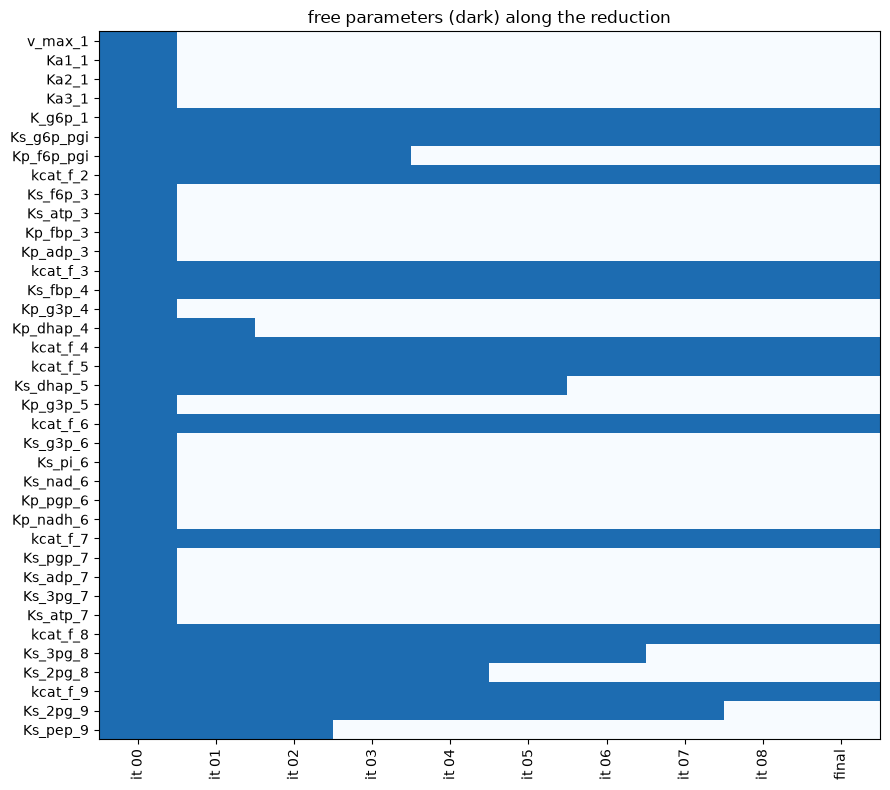

In [13]:
# the same matrix as a picture: parameters (rows, model order) against iterations, dark = free
numeric = matrix.drop(columns=[c for c in ("fixed by", "reaction") if c in matrix.columns])
fig, ax = plt.subplots(figsize=(max(6, 0.6 * numeric.shape[1] + 3), 8))
ax.imshow(numeric.to_numpy(dtype=float), aspect="auto", cmap="Blues", vmin=0, vmax=1.3)
ax.set_xticks(range(numeric.shape[1]))
ax.set_xticklabels(numeric.columns, rotation=90)
ax.set_yticks(range(len(ALL_PARAMS)))
ax.set_yticklabels(ALL_PARAMS)
ax.set_title("free parameters (dark) along the reduction")
fig.tight_layout()
plt.show()

In [14]:
# per iteration: the free set analysed, and the one after its fix (only runs that write the iter_XX files)
rows = []
for f in sorted(glob.glob(os.path.join(RED, "iter_*", "free_params.csv"))):
    d = os.path.dirname(f)
    now = pd.read_csv(f, index_col=0)
    nxt = read_optional(os.path.join(d, "next_free_params.csv"), index_col=0)
    rows.append({"iteration": os.path.basename(d)[5:], "n_free": int((now["status"] == "free").sum()),
                 "n_free_after_fix": int((nxt["status"] == "free").sum()) if nxt is not None else np.nan,
                 "fixed_in_this_iteration": ", ".join(p for p in now.index[(now["status"] == "free")]
                                                      if nxt is not None and nxt.loc[p, "status"] == "fixed")})

if rows:
    display(pd.DataFrame(rows).set_index("iteration"))
else:
    print("no iter_XX/free_params.csv in this run")

,n_free,n_free_after_fix,fixed_in_this_iteration
iteration,,,
00,37,18,"v_max_1, Ka1_1, Ka2_1, Ka3_1, Ks_f6p_3, Ks_atp_3, Kp_fbp_3, Kp_adp..."
01,18,17,Kp_dhap_4
02,17,16,Ks_pep_9
03,16,15,Kp_f6p_pgi
04,15,14,Ks_2pg_8
05,14,13,Ks_dhap_5
06,13,12,Ks_3pg_8
07,12,11,Ks_2pg_9
08,11,11,


## 11. Diagnostics of the iterations

**Structural check per iteration** (`structural_per_iteration.csv`): the smallest singular ratio of the rate-level matrix at the anchor and its minimum over the realizations, the gap to the next singular value (decades), the dimension of the consensus null space at the rate level and at the output level (bound-free and with the active set), the null groups found (`reaction:members[class, dim, exact dim]`) and the parameters kept free by the protections.

In [15]:
structural = read_optional(os.path.join(RED, "structural_per_iteration.csv"))
if structural is not None:
    cols = ["iter", "round", "n_free", "sigma_ratio_anchor", "sigma_ratio_min_over_runs", "gap_decades_to_next_anchor",
            "n_runs_with_ratio_below_cut", "null_dim_consensus", "out_null_dim", "out_null_dim_active_set",
            "out_n_identifiable", "out_n_bound_identified", "out_n_non_identifiable", "n_kept_free_by_rule", "kept_free_by_rule"]
    display(structural[[c for c in cols if c in structural.columns]].set_index(["iter", "round"]))

n_free  sigma_ratio_anchor  sigma_ratio_min_over_runs  gap_decades_to_next_anchor  n_runs_with_ratio_below_cut  null_dim_consensus  out_null_dim  out_null_dim_active_set  out_n_identifiable  \
iter round                                                                                                                                                                                                  
0    0          37        6.891950e-17               3.123792e-17                    0.161234                           11                   8            22                       20                  14   
     1          29        1.139231e-11               5.039570e-12                    4.044662                           11                   1            14                       14                  15   
     2          28        1.114261e-07               7.667085e-08                    0.584448                            0                   0            14                       14                  14   
     3          18        6.286217e-07               4.454375e-07                    0.824857                            0                   0             4                        3                  14   
1    0          18        6.286217e-07               4.970321e-07                    0.824857                            0                   0             4                        3                  14   
2    0          17        4.199970e-06               2.410824e-06                    1.257517                            0                   0             4                        3                  13   
3    0          16        4.199970e-06               2.253156e-06                    1.257517                            0                   0             4                        3                  12   
4    0          15        7.599116e-05               4.899858e-05                    0.528174                            0                   0             4                        3                  11   
5    0          14        2.564114e-04               1.033157e-04                    1.995370                            0                   0             4                        3                  10   
6    0          13        2.647531e-04               1.259449e-04                    1.995370                            0                   0             4                        3                   9   
7    0          12        2.893321e-04               5.893532e-05                    1.995370                            0                   0             4                        3                   8   
8    0          11        2.893321e-04               6.116252e-05                    1.995370                            0                   0             4                        3                   7   
     final      11        2.893321e-04               1.064430e-04                    1.995370                            0                   0             4                        3                   7   

            out_n_bound_identified  out_n_non_identifiable  n_kept_free_by_rule                   kept_free_by_rule  
iter round                                                                                                           
0    0                           1                      22                    0                                 NaN  
     1                           1                      13                    0                                 NaN  
     2                           0                      14                    4  K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7  
     3                           1                       3                    4  K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7  
1    0                           1                       3                    4  K_g6p_1;kcat_f_3;kcat_f_6;kcat_f_7  
2    0                           1                       3                    4  K_g6p_1;kcat_f_3;kcat_f_6;kca

**Singular spectra of the practical analysis.** For every iteration `iter_XX/spectrum.csv` has the singular values of $J_S$; the eigenvalue ratios $(\sigma_k/\sigma_1)^2$ are compared with the cut $10^{-8}$. The iterations that fix a parameter with R1 have values below the line; the loop stops when the smallest eigenvalue ratio is above it.

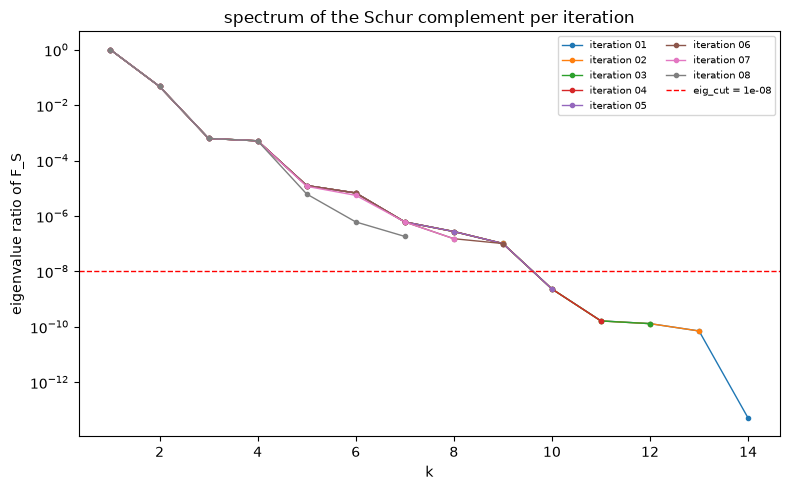

In [16]:
spec_files = sorted(glob.glob(os.path.join(RED, "iter_*", "spectrum.csv")))
fig, ax = plt.subplots(figsize=(8, 5))
for f in spec_files:
    sp = pd.read_csv(f)
    ax.semilogy(sp["k"] + 1, sp["sigma_ratio"] ** 2, "o-", ms=3, lw=1, label="iteration " + os.path.basename(os.path.dirname(f))[5:])

ax.axhline(THRESHOLDS["eig_cut"], color="red", ls="--", lw=1, label="eig_cut = %.0e" % THRESHOLDS["eig_cut"])
ax.set_xlabel("k")
ax.set_ylabel("eigenvalue ratio of F_S")
ax.legend(fontsize=7, ncol=2)
ax.set_title("spectrum of the Schur complement per iteration")
fig.tight_layout()
plt.show()

**Rank, R1 and R2 on the first practical iteration.** The files of the first practical iteration (`iter_01`) reproduce the rule logic from saved numbers: the rank at the cut from the spectrum, the rank-deficient case, the correlated pairs (only meaningful at full rank) and the parameters with a flag.

In [17]:
it_dir = os.path.join(RED, "iter_01")
spec = read_optional(os.path.join(it_dir, "spectrum.csv"))
infl = read_optional(os.path.join(it_dir, "influence.csv"), index_col=0)
pairs = read_optional(os.path.join(it_dir, "corr_pairs.csv"))

if spec is not None:
    eig_ratio = spec["sigma_ratio"].to_numpy() ** 2
    rank = int((eig_ratio > THRESHOLDS["eig_cut"]).sum())
    print("iteration 1: %d analysed parameters, rank %d at the cut %.0e -> %s" % (
        len(spec), rank, THRESHOLDS["eig_cut"], "full rank: R2 may act" if rank == len(spec) else "RANK DEFICIENT: R1 acts, R2 is not used"))

if infl is not None:
    print("\nR0: structural zeros (influence < %.0e * max):" % THRESHOLDS["zero_cut"],
          list(infl.index[infl["influence"] < THRESHOLDS["zero_cut"] * infl["influence"].max()]))
    print("R3: flagged parameters:", {p: f for p, f in infl["flags"].dropna().items()})

if pairs is not None:
    print("\ncorrelated pairs |r| > %.2f (computed even at rank deficiency, acted on only at full rank):" % THRESHOLDS["corr_threshold"])
    display(pairs)

iteration 1: 14 analysed parameters, rank 9 at the cut 1e-08 -> RANK DEFICIENT: R1 acts, R2 is not used

R0: structural zeros (influence < 1e-06 * max): []
R3: flagged parameters: {'kcat_f_6': 'fd_unstable', 'Ks_2pg_9': 'fd_unstable'}

correlated pairs |r| > 0.90 (computed even at rank deficiency, acted on only at full rank):


,p1,p2,r
0,kcat_f_5,Ks_dhap_5,-0.998829
1,Ks_3pg_8,Ks_pep_9,0.996638
2,Ks_g6p_pgi,Kp_f6p_pgi,0.980615
3,kcat_f_8,Ks_pep_9,0.976196
4,Kp_dhap_4,Ks_pep_9,0.974852
5,Kp_dhap_4,Ks_3pg_8,0.963774
6,kcat_f_8,Ks_3pg_8,0.962954
7,Kp_dhap_4,kcat_f_8,0.927156


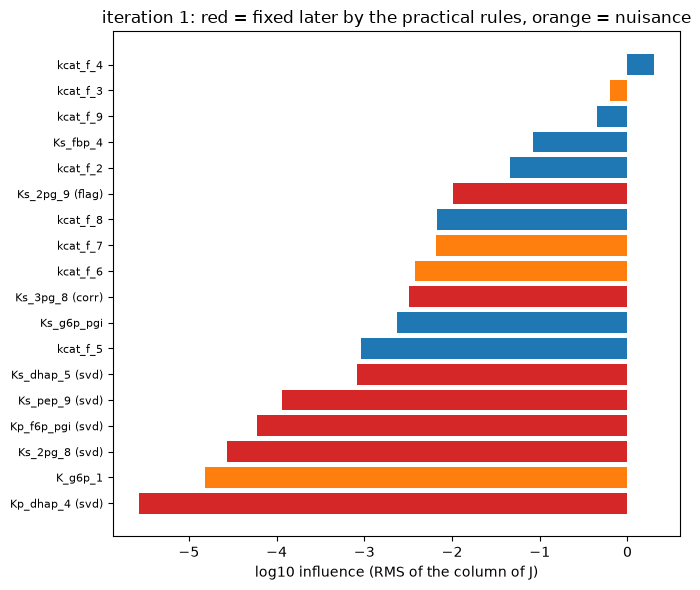

In [18]:
# influence of the free parameters at the first practical iteration, coloured by what happened to them
if infl is not None and fix_log is not None:
    fixed_rule = fix_log[fix_log["iter"] >= 1].set_index("param")["rule"].to_dict()
    order = infl["influence"].sort_values()
    colors = ["tab:red" if p in fixed_rule else ("tab:orange" if infl.loc[p, "kept_free_by_rule"] else "tab:blue") for p in order.index]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(range(len(order)), np.log10(order.to_numpy()), color=colors)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(["%s (%s)" % (p, fixed_rule.get(p, "")) if p in fixed_rule else p for p in order.index], fontsize=8)
    ax.set_xlabel("log10 influence (RMS of the column of J)")
    ax.set_title("iteration 1: red = fixed later by the practical rules, orange = nuisance")
    fig.tight_layout()
    plt.show()

## 12. The final structure

`reduction/final_structure.csv` lists all 37 parameters with their status. For the free ones the class (`identifiable`: bound-free output-level test passes and the parameter is not flagged; `bound_identified`; `non_identifiable`; `kept_free_by_rule`: nuisance; `flagged`), the influence and the Schur CV; for the fixed ones the iteration and the rule that fixed them. These CVs are indicative only: the point of the selection is the structure; uncertainty is quantified by the bootstrap and the profiles. The final re-estimate, covariance cross-check and metrics are in `final_fit.ipynb`.

In [19]:
final_structure = read_optional(os.path.join(RED, "final_structure.csv"))
if final_structure is not None:
    cols = ["param", "status", "value", "fixed_iter", "fixed_rule", "ident_class", "output_class", "flags", "influence",
            "cv_percent", "cv_basis"]
    fs = final_structure[[c for c in cols if c in final_structure.columns]].set_index("param")
    print("%d free, %d fixed" % ((fs["status"] == "free").sum(), (fs["status"] == "fixed").sum()))
    display(fs[fs["status"] == "free"])
    display(fs[fs["status"] == "fixed"][["value", "fixed_iter", "fixed_rule"]])

11 free, 26 fixed


,status,value,fixed_iter,fixed_rule,ident_class,output_class,flags,influence,cv_percent,cv_basis
param,,,,,,,,,,
K_g6p_1,free,9.994917,NaN,NaN,kept_free_by_rule,non_identifiable,NaN,0.000015,0.187928,nuisance_conditional
Ks_g6p_pgi,free,0.034426,NaN,NaN,identifiable,identifiable,NaN,0.002377,4382.416306,schur
kcat_f_2,free,984.659833,NaN,NaN,identifiable,identifiable,NaN,0.045514,227.508742,schur
kcat_f_3,free,982.061399,NaN,NaN,kept_free_by_rule,bound_identified,NaN,0.633123,11.201284,nuisance_conditional
Ks_fbp_4,free,0.001019,NaN,NaN,identifiable,identifiable,NaN,0.083804,137.452731,schur
kcat_f_4,free,2.697854,NaN,NaN,identifiable,identifiable,NaN,2.017814,5.698225,schur
kcat_f_5,free,6365.317053,NaN,NaN,identifiable,identifiable,NaN,0.000907,8009.622326,schur
kcat_f_6,free,443.983469,NaN,NaN,kept_free_by_rule,non_identifiable,fd_unstable,0.003761,1847.950802,nuisance_conditional
kcat_f_7,free,897.217134,NaN,NaN,kept_free_by_rule,non_identifiable,NaN,0.006636,1080.541430,nuisance_conditional


,value,fixed_iter,fixed_rule
param,,,
v_max_1,80.209416,0.0,structural_output
Ka1_1,0.094564,0.0,structural_output
Ka2_1,0.975483,0.0,structural_output
Ka3_1,0.731318,0.0,structural_output
Kp_f6p_pgi,10.371590,3.0,svd
Ks_f6p_3,3.579306,0.0,structural_output
Ks_atp_3,0.001972,0.0,structural_exact
Kp_fbp_3,0.007364,0.0,structural_output
Kp_adp_3,0.002101,0.0,structural_exact


In [20]:
if final_structure is not None:
    free_names = list(final_structure.loc[final_structure["status"] == "free", "param"])
    free_by_reaction = {}
    for reaction in RXN_ORDER:
        free_by_reaction[reaction] = [p for p in free_names if RXN_OF_PARAM[p] == reaction]
    print("free parameters per reaction (every reaction keeps at least one):")
    display(pd.Series(free_by_reaction).to_frame("free"))

free parameters per reaction (every reaction keeps at least one):


,free
pts,[K_g6p_1]
pgi,"[Ks_g6p_pgi, kcat_f_2]"
pfk,[kcat_f_3]
fba,"[Ks_fbp_4, kcat_f_4]"
tpi,[kcat_f_5]
gap,[kcat_f_6]
pgk,[kcat_f_7]
gpm,[kcat_f_8]
eno,[kcat_f_9]
